# Do CV-parser errors reach the selection? A fairness audit of the Adecco reverse matching

**AI Ethics, Module 2 – Hiring CV Bias** · Francesco Baiocchi, Leonardo Petrilli

**Where this study comes from.** In the Hiring CV Bias project we studied a proprietary parser that extracts skills
from anonymized CVs for Adecco. After cleaning the CVs and the parser output (`data_cleaning`), we looked for
imbalances between demographic groups in the extracted skills (`distributions_analysis`) and measured the parser's
errors directly (`bias_detection`): rule-based extractors for driving licenses and language skills, and exact and
semantic matching for job titles, found information that is in the CV text but missing from the parser output, and
compared the miss rates across gender and macro-region. Those false negatives are the starting point here.

**The question.** A parser error matters only if it changes a decision. Adecco's *reverse matching* takes a job
offer and ranks the candidates by a match score computed from the parsed profile. This study asks whether the parser's
errors reach that ranking, and whether they do so unevenly across groups.

* **RQ1** – Do the errors of the CV parser propagate to the selection on the job offers, and do they penalize some
  groups (gender, macro-region, women of the South) more than others?
* **RQ2** – Does correcting the parser work as a fairness mitigation, compared with the standard techniques
  (reweighing, in-processing, post-processing)?
* **RQ3** – Which pieces of information drive the effect, and how robust are the conclusions to our choices?

**Pipeline under study**

```
CV ──parser──► profile ──matcher──► score for every (candidate, job) ──► position in the job's list
```

**Three versions of every candidate profile**

| version | content | role |
|---|---|---|
| **P** | the real Adecco profile (`Candidates` sheet) | validates the reconstructed matcher |
| **O** – Original | licenses, languages, job titles **only as read by the parser** | the fully automatic pipeline |
| **C** – Corrected | O + the false negatives recovered from the CV text | the pre-processing mitigation |


In [ ]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import polars as pl

%matplotlib inline
warnings.filterwarnings("ignore")

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_float_precision(4)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


polars.config.Config

## Phase 1 – Data and audit

### 1.1 Loading, groups and lists

`ReverseMatching.xlsx` holds 51,490 (candidate, job) pairs for 7,769 candidates and 9,310 jobs. The cleaning of the
raw CVs (`data_cleaning`) kept 7,521 candidates with a usable CV; we keep their pairs. Twenty-two pairs are exact
duplicates and are removed.

In [ ]:
from hiring_cv_bias.config import CLEANED_REVERSE_MATCHING_PATH, REVERSE_MATCHING_PATH
from hiring_cv_bias.reverse_matching.loader import dedupe_pairs
from hiring_cv_bias.utils import load_data, load_excel_sheets

raw = load_excel_sheets(
    REVERSE_MATCHING_PATH, ["ReverseMatching", "Candidates", "Jobs"]
)
pairs_all = dedupe_pairs(raw["ReverseMatching"])
clean = load_data(CLEANED_REVERSE_MATCHING_PATH)

n_raw = raw["ReverseMatching"].height
print(
    f"pairs: {n_raw} → {pairs_all.height} after removing {n_raw - pairs_all.height} duplicates"
)
print(
    f"candidates: {raw['Candidates'].height} in the file, {clean.height} with a clean CV"
)

pairs: 51490 → 51468 after removing 22 duplicates
candidates: 7769 in the file, 7521 with a clean CV


#### Sensitive attributes

The sensitive attributes are **Gender** and **Location** (macro-region) and their intersection. `Other` (106) and
`Unknown` (11) candidates are too few for group statistics and are excluded from the fairness tables.

In [ ]:
display(clean.group_by("Gender", "Location").len().sort("Gender", "Location"))

Gender,Location,len
str,str,u32
"""Female""","""CENTER""",505
"""Female""","""NORTH""",2458
"""Female""","""SOUTH""",457
"""Male""","""CENTER""",496
"""Male""","""NORTH""",2885
"""Male""","""SOUTH""",603
"""Other""","""CENTER""",22
"""Other""","""NORTH""",50
"""Other""","""SOUTH""",34


`Age_bucket` is a deterministic function of `Gender` in the Adecco file (all women 55–74, all men 25–34): it is
corrupted and is **never used**.

In [ ]:
display(clean.group_by("Gender", "Age_bucket").len().sort("Gender", "Age_bucket"))

Gender,Age_bucket,len
str,str,u32
"""Female""","""55-74""",3420
"""Male""","""25-34""",3984
"""Other""","""45-54""",106
"""Unknown""","""Unknown""",11


#### List lengths

Each row is a (candidate, job) pair, so counting the rows of each job gives the length of its list. Lists are short:
the median job has 3 candidates, and only 3,431 jobs have at least 5. Phase 2 keeps only lists with at least 5 Female
or Male candidates, because a position within a list of one or two candidates says nothing about selection.

In [ ]:
from hiring_cv_bias.reverse_matching.audit import list_lengths

display(list_lengths(pairs_all.join(clean.select("CANDIDATE_ID"), on="CANDIDATE_ID")))

jobs,median,mean,max,jobs_ge_5
i64,f64,f64,i64,i64
9238,3.0000,5.4023,109,3431


### 1.2 The score: outliers and the formula

For every pair `ReverseMatching.xlsx` gives the `match_score` and the seven components computed by Adecco, but not how
they are combined.

#### Range of the components

For each column the table gives the number of distinct values and the range. Four components are binary (0 or 1):
`Interest`, `Card_match`, `Languages_match` and `Regulated_Trainings_match`. `Distance_match` takes three values, from
0.2 to 1 (every pair is within 25 km). `match_skills` (a share, 64 values) and `Experience` (a similarity, 1,495 values)
are continuous between 0 and 1. So every component lies in [0, 1]; `match_score` goes from 2.0 to 33.8: we look at its distribution next.

In [ ]:
from hiring_cv_bias.reverse_matching.scoring import COMPONENTS

display(
    pairs_all.select(
        pl.struct(
            n_values=pl.col(c).n_unique(), min=pl.col(c).min(), max=pl.col(c).max()
        ).alias(c)
        for c in COMPONENTS + ["match_score"]
    )
    .unpivot(variable_name="column")
    .unnest("value")
)

column,n_values,min,max
str,u32,f64,f64
"""Experience""",1495,0.0000,1.0000
"""Interest""",2,0.0000,1.0000
"""Card_match""",2,0.0000,1.0000
"""Languages_match""",2,0.0000,1.0000
"""Regulated_Trainings_match""",2,0.0000,1.0000
"""match_skills""",64,0.0000,1.0000
"""Distance_match""",3,0.2000,1.0000
"""match_score""",5621,2.0030,33.7621


#### Distance bands

`Distance_match` takes only three values, but `ReverseMatching.xlsx` also gives the distance in km (`distance_km`).
Grouping the pairs by `Distance_match` shows the km range behind each value: 1 below 10 km, 0.6 from 10 to 20 km, 0.2
from 20 to 25 km. The ranges do not overlap, so `Distance_match` is a step function of the distance, and we use these
bands to recompute it in Component rules.

In [ ]:
display(
    pairs_all.group_by("Distance_match")
    .agg(
        pl.len().alias("pairs"),
        pl.col("distance_km").min().alias("km_min"),
        pl.col("distance_km").max().alias("km_max"),
    )
    .sort("Distance_match", descending=True)
)

Distance_match,pairs,km_min,km_max
f64,u32,f64,f64
1.0000,23296,0.0000,9.9998
0.6000,19603,10.0039,19.9999
0.2000,8569,20.0002,24.9987


#### Outliers

The box is narrow and most scores are below 6. A small group forms a long right tail up to 33.8. Outliers follow the
standard box-plot rule: a pair is an outlier when its score lies above the upper whisker (red dashed line: third
quartile + 1.5 × box height). The lower whisker is below the minimum score, so there are no low outliers. The second
printed line counts them: 1,110 pairs (2.2%), above 6.41, against a third quartile of 4.65. Whether they
follow the same rule as the other pairs cannot be judged from the distribution alone, so we study how the score is
built on the other 97.8% and test the outliers against the result in Exact check. We set aside the pairs only, not the
candidates.


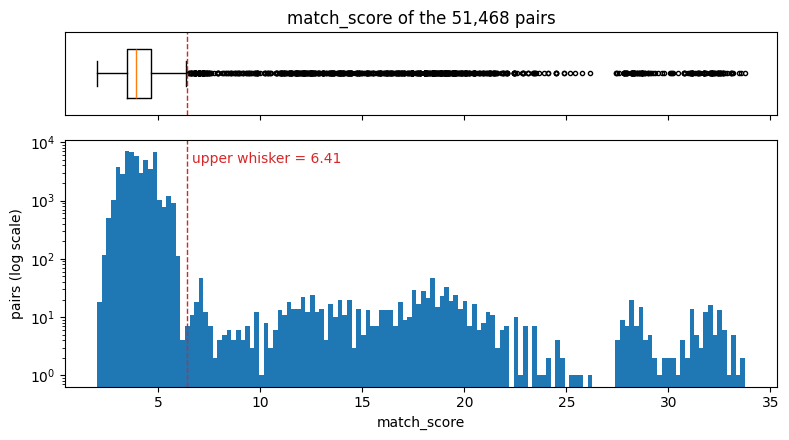

In [ ]:
from hiring_cv_bias.fairness.plots import plot_score_distribution
from hiring_cv_bias.reverse_matching.scoring import score_outliers

q1, q3 = pairs_all.select(
    pl.col("match_score").quantile(0.25).alias("q1"),
    pl.col("match_score").quantile(0.75).alias("q3"),
).row(0)
threshold = q3 + 1.5 * (q3 - q1)
is_outlier = score_outliers(pairs_all)
pairs_clean = pairs_all.filter(~is_outlier)

fig = plot_score_distribution(
    pairs_all["match_score"].to_list(),
    threshold,
    title=f"match_score of the {pairs_all.height:,} pairs",
)
plt.show()

In [ ]:
outliers = pairs_all.filter(is_outlier)
print(
    f"box: Q1 = {q1:.2f}, Q3 = {q3:.2f} | lower whisker = {q1 - 1.5 * (q3 - q1):.2f}, "
    f"minimum score = {pairs_all['match_score'].min():.2f}"
)
print(
    f"outliers: {outliers.height} pairs ({outliers.height / pairs_all.height:.1%}) above {threshold:.2f}, "
    f"in {outliers['Job_id'].n_unique()} of {pairs_all['Job_id'].n_unique()} jobs"
)

box: Q1 = 3.47, Q3 = 4.65 | lower whisker = 1.71, minimum score = 2.00
outliers: 1110 pairs (2.2%) above 6.41, in 143 of 9310 jobs


#### Weights

We start from the simplest hypothesis, a weighted sum, fitted by least squares on the pairs without outliers:

$$\text{match\_score} \approx w_0 + w_1\,\text{Experience} + w_2\,\text{Interest} + \dots + w_7\,\text{Distance\_match}$$

The estimates are almost round numbers. Rounded to one decimal:

$$\text{score} = 2\,\text{Experience} + \text{Interest} + \text{match\_skills} + \text{Distance} + 0.3\,(\text{Card} + \text{Languages} + \text{Regulated})$$

The last row is the same regression on all pairs: with the outliers, `Experience` weighs 6, `Languages_match` is
negative and the intercept is −3.3.


In [ ]:
from hiring_cv_bias.reverse_matching.scoring import fit_weights

estimated = fit_weights(pairs_clean)
weights = {k: round(v, 1) for k, v in estimated.items()}
display(
    pl.DataFrame(
        [
            {"weights": "estimated, without outliers", **estimated},
            {"weights": "rounded to one decimal", **weights},
            {
                "weights": "estimated, all pairs",
                **fit_weights(pairs_all),
            },
        ]
    )
)

weights,Experience,Interest,Card_match,Languages_match,Regulated_Trainings_match,match_skills,Distance_match,intercept
str,f64,f64,f64,f64,f64,f64,f64,f64
"""estimated, without outliers""",2.0368,0.9957,0.3001,0.2926,0.3038,0.9986,0.9954,-0.0244
"""rounded to one decimal""",2.0000,1.0000,0.3000,0.3000,0.3000,1.0000,1.0000,-0.0000
"""estimated, all pairs""",6.0832,0.8798,0.5379,-0.0922,0.5666,1.1177,0.4918,-3.3084


#### Exact check

A good fit is not enough: an approximate formula would leave a small error on every pair. So we count the scores the
rounded formula reproduces exactly (`share_exact`, error < 10⁻⁴): on the pairs without outliers it is almost all of
them, so the score *is* this formula.
The printed example recomputes one pair by hand.

The formula does not tell where the outliers come from, it only rules itself out: with every component at its maximum
of 1 it gives 2 + 1 + 1 + 1 + 3 × 0.3 = 5.9, below the outlier threshold of 6.41. So the outlier scores contain
something outside the seven components, which the data does not show, and we leave those pairs out of the study.


In [ ]:
from hiring_cv_bias.reverse_matching.scoring import validate_formula

display(validate_formula(pairs_clean, weights))

example = pairs_clean.row(0, named=True)
terms = " + ".join(f"{weights[c]:g}·{example[c]:.4f}" for c in COMPONENTS if example[c])
formula_value = sum(weights[c] * example[c] for c in COMPONENTS)
print(
    f"worked example, pair ({example['CANDIDATE_ID']}, {example['Job_id']}): "
    f"{terms} = {formula_value:.4f}; Adecco's score = {example['match_score']:.4f}"
)

n_pairs,share_exact,n_pairs_off,n_jobs_off,residual_min,residual_max
i64,f64,i64,i64,f64,f64
50358,0.9988,60,16,0.9271,3.6915


worked example, pair (6268443, ORD_999_1519): 2·0.9477 + 0.3·1.0000 + 0.3·1.0000 + 0.3·1.0000 + 1·0.6000 = 3.3955; Adecco's score = 3.3955


#### Component rules

Five of the seven components can be recomputed from two things we have: the candidate's profile and the job's
requirements (the `Jobs` sheet). For a pair:

- `Card_match`: 1 if the candidate has every driving license the job asks for, else 0.
- `Languages_match`: the same with the languages.
- `Regulated_Trainings_match`: the same with the regulated trainings, the formal qualifications a job can require (in
  the example below, a field of study).
- `match_skills`: the share of the skills the job asks for that the candidate has (`matterknowledge` in the data).
- `Distance_match`: from the distance bands above.

For the three binary components a job that asks for nothing gives 1; for `match_skills` it gives 0 (see below).

The table describes the job requirements behind these rules, one row per requirement (`req_licenses` for
`Card_match`, `req_languages` for `Languages_match`, `req_regulated` for `Regulated_Trainings_match`, `req_skills` for
`match_skills`). `share_jobs` is the share of jobs that ask for at least one item of that kind, and `example` is the
requirement of the first such job.

In [ ]:
from hiring_cv_bias.reverse_matching.components import job_requirements

jobs_req = job_requirements(raw["Jobs"])
display(
    jobs_req.select(
        pl.struct(
            share_jobs=(pl.col(c).list.len() > 0).mean(),
            example=pl.col(c).filter(pl.col(c).list.len() > 0).first().list.join("; "),
        ).alias(c)
        for c in ["req_licenses", "req_languages", "req_regulated", "req_skills"]
    )
    .unpivot(variable_name="requirement")
    .unnest("value")
)

requirement,share_jobs,example
str,f64,str
"""req_licenses""",0.3014,"""b"""
"""req_languages""",0.1589,"""francese; inglese"""
"""req_regulated""",0.0104,"""marketing"""
"""req_skills""",0.4878,"""procedure di organizzazione lo…"


To check the rules we apply them to the real profile (P) of every pair and compare the result with the value
Adecco gives in `ReverseMatching.xlsx`. The **agreement** of a component is the share of pairs where the two values are
equal. All five agree on more than 99% of the pairs, so the rules are the ones Adecco uses.

`Interest` comes from the categories the candidate selects, not from the CV: the parser does not extract it, so it is
the same in every version of the dataset. `Experience` cannot be recomputed from the data; we estimate it in 1.3.

In [ ]:
from hiring_cv_bias.reverse_matching.audit import rules_agreement
from hiring_cv_bias.reverse_matching.profiles import build_profile_real

display(rules_agreement(pairs_all, build_profile_real(raw["Candidates"]), jobs_req))

component,agreement
str,f64
"""Card_match""",0.9914
"""Languages_match""",0.9943
"""Regulated_Trainings_match""",0.9997
"""match_skills""",0.9992
"""Distance_match""",1.0000


`match_skills` needs one more choice: when a job asks for no skill the share is 0/0. The first table takes the pairs
whose job has an empty `req_skills` and counts Adecco's `match_skills`: almost all are 0, so our rule gives 0.

The second table lists the exceptions: pairs where Adecco gives a share of skills (1, 0.889, 0.5) although the `Jobs`
sheet lists no skill for the job. The values look like shares of a
real list (0.889 = 8 of 9 skills), so Adecco probably scored these jobs with a skill list that is not in our export; we
cannot check it. These pairs are part of why the agreement of `match_skills` is not 1. In P, O and C our rule gives them 0.

In [ ]:
no_skills = pairs_all.join(jobs_req.select("Job_id", "req_skills"), on="Job_id").filter(
    pl.col("req_skills").list.len() == 0
)
display(no_skills.group_by("match_skills").len().sort("match_skills"))
display(
    no_skills.filter(pl.col("match_skills") > 0)
    .select("Job_id", "CANDIDATE_ID", "match_skills")
    .sort("Job_id")
)

match_skills,len
f64,u32
0.0000,22829
0.5000,3
0.8889,2
1.0000,4


Job_id,CANDIDATE_ID,match_skills
str,i64,f64
"""ORD_16897_0126""",6011795,0.5000
"""ORD_16897_0126""",5278670,0.5000
"""ORD_16897_0126""",1396919,0.5000
"""ORD_17630_0015""",7660087,1.0000
"""ORD_17726_0064""",4086666,1.0000
"""ORD_17726_0064""",863361,1.0000
"""ORD_28945_0565""",5918129,1.0000
"""ORD_28945_0565""",4517254,0.8889
"""ORD_28945_0565""",163255,0.8889


### 1.3 Estimating `Experience` from job titles

To re-score O and C we need all seven components for each version. Six are recomputed with the rules of 1.2.
`Experience` cannot be: Adecco computes it with an internal model that compares the job category with the candidate's
past job titles, and we do not have that model. We estimate it in three steps.

**1. Raw similarity.** A multilingual sentence-embedding model (`paraphrase-multilingual-MiniLM-L12-v2`) turns the job
category and every title into vectors; texts with a similar meaning get similar vectors, also across languages. For
each pair the raw similarity is 1 if the job category appears verbatim among the titles, 0 if the candidate has no
titles, otherwise the highest cosine similarity between the category and the titles (the past job closest to the offer).

**2. Calibration on P.** The raw similarity orders the pairs sensibly but is on the wrong scale, so on the real profile
P, where we know both numbers for every pair, we learn a curve from raw similarity to `Experience` with *isotonic
regression*: the pairs are sorted by raw similarity, each value gets the average real `Experience`, and adjacent groups
are merged whenever the curve would go down. The result is a step function that never decreases: a title more similar
to the job never gets a lower `Experience`.

**3. The same curve for every version.** The curve is learned once, on P, and applied to P, O and C. P also uses the
*estimated* `Experience`, so the three versions are scored in exactly the same way and differences between versions come
only from the titles.

#### Building the dataset

The build step (`python -m hiring_cv_bias.reverse_matching.build`) runs the three steps above for every pair and
writes the result to `data/ethics/pairs.parquet`. It also prints how close the estimate is to the real `Experience`,
measured on P, the only version where the real value is known:

* `pearson` – linear correlation between estimate and real value. Close to 1 means that when the real `Experience`
  goes up, the estimate goes up by a proportional amount.
* `spearman` – correlation between the two *rankings*. It ignores the scale and only asks whether the pairs are
  ordered the same way, which is what matters for a position in a job's list.
* `mae` – mean absolute error, the average distance between estimate and real value. `Experience` lies in [0, 1] and
  weighs 2 in the score, so an error of e on `Experience` moves the score by 2e.
* `share_exact_1_recovered` – among the pairs where the real `Experience` is exactly 1 (the job category is one of
  the candidate's titles), the share whose estimate is 0.99 or above. It checks that the estimator does not lose the
  verbatim matches, the most frequent and most valuable case.

In [ ]:
from hiring_cv_bias.reverse_matching.build import build_dataset

result = build_dataset()
pairs = result.pairs
print(
    "Experience estimator on P:",
    {k: round(v, 3) for k, v in result.experience_diagnostics.items()},
)
print(
    f"pairs dataset: {pairs.height} rows, {pairs['CANDIDATE_ID'].n_unique()} candidates, "
    f"{pairs['Job_id'].n_unique()} jobs"
)

Experience estimator on P: {'pearson': 0.839, 'spearman': 0.846, 'mae': 0.015, 'share_exact_1_recovered': 0.995}
pairs dataset: 48816 rows, 7517 candidates, 9180 jobs


#### What the calibration does

The table groups the pairs of P by raw similarity. Compare `raw_mean` with `real_mean` to see the scale problem:
Adecco's `Experience` stays high even for loosely related titles, while the raw similarity drops much lower. Compare
`calibrated_mean` with `real_mean` to see that the curve fixes it.

The figure shows the same thing: the orange dots are the real `Experience` averaged in 20 bins of raw similarity, the
blue steps are the calibration curve, and the dotted diagonal is the reference "estimate = raw similarity", i.e. what we
would get without calibration. The dots rise with the similarity but stay far above the diagonal, which is the scale
gap the curve corrects.

In [ ]:
from hiring_cv_bias.reverse_matching.experience import calibration_table

display(calibration_table(pairs))

group,n_pairs,raw_mean,real_mean,calibrated_mean
str,u32,f32,f64,f64
"""no titles (raw = 0)""",7,0.0000,0.0000,0.0000
"""(0, 0.6)""",4013,0.4883,0.9112,0.9081
"""[0.6, 0.7)""",6741,0.6527,0.9151,0.9140
"""[0.7, 0.8)""",5063,0.7483,0.9214,0.9243
"""[0.8, 0.9)""",17784,0.8431,0.9613,0.9594
"""[0.9, 1)""",4394,0.9335,0.9558,0.9644
"""verbatim match (raw = 1)""",10814,1.0000,0.9950,0.9950


In the plot, the blue steps are the learned curve, the orange dots the real `Experience` averaged in 20 bins of raw
similarity, and the dotted line what we would use without calibration. Where the orange dots go down while the raw
similarity goes up, the blue curve stays flat: that is the merging rule of step 2.

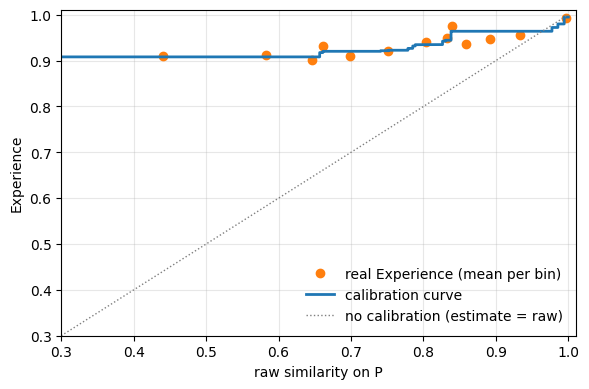

In [ ]:
from hiring_cv_bias.fairness.plots import plot_calibration_curve

fig = plot_calibration_curve(pairs)
plt.show()

### 1.4 The three profile versions

#### Fields per version

For every field and version: the mean number of items per candidate and the share of candidates with at least one
item. `regulated` and `skills` are copied from P in every version (the parser does not produce them and no false
negatives were collected for them), so they are identical across rows. From O to C the correction recovers what the
parser missed: licenses go from 28% to 59% of the candidates, languages from 88% to 98%, job titles from 91% to 95%.

In [ ]:
from hiring_cv_bias.reverse_matching.audit import profile_field_stats

profiles = result.profiles
display(profile_field_stats(profiles))

version,licenses,licenses_nonempty,languages,languages_nonempty,regulated,regulated_nonempty,skills,skills_nonempty,experience,experience_nonempty
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""P""",0.6639,0.5236,0.8639,0.4663,0.5505,0.4491,4.4052,0.4929,5.5249,0.9997
"""O""",0.3036,0.2782,1.7321,0.8787,0.5505,0.4491,4.4052,0.4929,3.0797,0.9123
"""C""",0.6184,0.5929,2.4270,0.9781,0.5505,0.4491,4.4052,0.4929,3.6510,0.9452


#### The real profile is not the parser output

If P came from the parser it would look like O; it does not (P has more licenses and fewer languages than O). The table
compares P and O candidate by candidate. The parser found a license for 2,161 candidates, but only 17% of them have any
license in P; it found languages for 6,827 candidates, 39% of whom have a language in P, and when both have one the
lists share an item in 18% of the cases. Job titles are different: almost every candidate with parsed titles has
titles in P and half of them share at least one. So `experience` comes from the parser (titles translated to Italian,
plus manually added ones: the lists are almost never identical), while licenses and languages were entered by hand: the
real matcher used a **partly manual** profile.

We do not know where the manual fields come from (a correction of the parser, or information that was never in the CV,
e.g. from an interview), so we do not use P to judge the parser: the parser's bias is measured on the Original vs
Corrected comparison only. P serves to validate the rules (1.2) and the `Experience` estimate (1.3).

In [ ]:
from hiring_cv_bias.reverse_matching.audit import profile_overlap

display(profile_overlap(profiles["P"], profiles["O"]))

field,candidates_parser,share_also_in_real,share_common_item,share_identical
str,i32,f64,f64,f64
"""licenses""",2161,0.1749,0.4603,0.4048
"""languages""",6827,0.3934,0.1791,0.0343
"""experience""",7088,1.0000,0.5044,0.0003


#### Differences at the pair level

Share of pairs where each component (and the score) differs between versions. Regulated trainings, skills and distance
never change. The parser misses the license in 19% of the pairs of the real profile; the correction changes the license
in 10% of the pairs and the score in 22%.

In [ ]:
from hiring_cv_bias.reverse_matching.audit import version_differences

display(
    pl.concat(
        [version_differences(pairs, "P", "O"), version_differences(pairs, "O", "C")]
    ).pivot(on="comparison", index="column", values="share_different")
)

column,P vs O,O vs C
str,f64,f64
"""Card_match""",0.1897,0.0954
"""Languages_match""",0.1325,0.0641
"""Regulated_Trainings_match""",0.0000,0.0000
"""match_skills""",0.0000,0.0000
"""Distance_match""",0.0000,0.0000
"""Experience_hat""",0.7561,0.0866
"""score""",0.8448,0.2203
